#### Цель
Продолжить часть I: добавить ансамбли, настроить их по стратифицированной кросс-валидации и сравнить с базовыми моделями в сценарии раннего выявления риска.
#### Данные и ограничение
Используй тот же датасет UCI и allowlist признаков на момент поступления из части I. Семестровые результаты запрещены и в этой части.  
Достаточно Jupyter-ноутбука. Продолжай тот же репозиторий из части I на ветке clf/students_dropout/part_2; результат части I сохраняй на clf/students_dropout/part_1, а требования проекта из части III будут добавлены на clf/students_dropout/part_3.
#### Задание
* Единая схема эксперимента: оставь test-набор для финальной проверки. На train проведи StratifiedKFold; подготовка признаков должна быть частью pipeline, чтобы преобразования не видели validation-fold.
* Ансамбли и бустинги: обучи случайный лес, градиентный бустинг и минимум один библиотечный бустинг: XGBoost, LightGBM или CatBoost. Для CatBoost отдельно объясни, используешь ли нативную работу с категориальными признаками или общий one-hot pipeline. Подбери ключевые гиперпараметры через GridSearchCV или RandomizedSearchCV, обоснуй диапазоны поиска и укажи, по какой метрике происходит refit.
* Сравнение: для baseline, логистической регрессии, дерева и ансамблей покажи среднее и разброс CV macro F1, затем одну финальную test-оценку. Добавь classification report, weighted F1, balanced accuracy и confusion matrix лучшей модели.
* Анализ ошибок: разберись, какие классы чаще путаются и какие признаки наиболее важны для ансамблей. Не интерпретируй важность как причинность и не делай выводов о человеке по одной модели.
* Решение: выбери модель для предложения ранней поддержки. Объясни, почему для этой цели риск пропустить будущий Dropout и риск ошибочно отнести студента к группе риска требуют анализа precision и recall именно этого класса.

#### 1. Библиотеки и модули

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    make_scorer,
)
from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

import lightgbm
from lightgbm import LGBMClassifier

In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_ITER_SEARCH = 12
CLASS_ORDER = ["Dropout", "Enrolled", "Graduate"]

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
warnings.filterwarnings("error", category=ConvergenceWarning)

print({
    "Python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "lightgbm": lightgbm.__version__,
})

{'Python': '3.12.2', 'numpy': '2.5.2', 'pandas': '3.0.5', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.1', 'lightgbm': '4.7.0'}


#### 2. Загрузка тех же данных
Логика загрузки повторяет часть I (data/raw/data.csv)

In [3]:
DATA_PATH = Path("data/raw/data.csv")
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/697/"
    "predict+students+dropout+and+academic+success.zip"
)

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    try:
        with urlopen(DATA_URL, timeout=60) as response:
            archive_bytes = response.read()
        with ZipFile(BytesIO(archive_bytes)) as archive:
            csv_bytes = archive.read("data.csv")
        DATA_PATH.write_bytes(csv_bytes)
    except Exception as exc:
        raise RuntimeError(
            "Не удалось скачать UCI. Поместите data.csv в data/raw/ и повторите запуск."
        ) from exc

print("SHA-256 исходного CSV:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
df = pd.read_csv(DATA_PATH, sep=";")
df.columns = df.columns.str.strip()

assert df.columns.is_unique
assert df.shape == (4424, 37), f"Неожиданная версия данных: {df.shape}"
assert df["Target"].notna().all()
assert set(df["Target"].unique()) == set(CLASS_ORDER)

print(f"Строк: {len(df):,}; признаков: {df.shape[1] - 1}; target: Target")

SHA-256 исходного CSV: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae
Строк: 4,424; признаков: 36; target: Target


#### 3. Тот же allowlist на момент поступления
Используем ровно ту же policy из части I: 18 разрешённых признаков, 12 семестровых полей запрещены, ещё 6 полей с неоднозначным моментом доступности не включаются.

In [4]:
FEATURE_SPEC = [
    ("Marital status", "category"),
    ("Application mode", "category"),
    ("Application order", "category"),
    ("Course", "category"),
    ("Daytime/evening attendance", "category"),
    ("Previous qualification", "category"),
    ("Previous qualification (grade)", "numeric"),
    ("Nacionality", "category"),
    ("Mother's qualification", "category"),
    ("Father's qualification", "category"),
    ("Mother's occupation", "category"),
    ("Father's occupation", "category"),
    ("Admission grade", "numeric"),
    ("Displaced", "category"),
    ("Educational special needs", "category"),
    ("Gender", "category"),
    ("Age at enrollment", "numeric"),
    ("International", "category"),
]

ALLOWLIST = [name for name, _ in FEATURE_SPEC]
CAT_FEATURES = [name for name, kind in FEATURE_SPEC if kind == "category"]
NUM_FEATURES = [name for name, kind in FEATURE_SPEC if kind == "numeric"]

UNCERTAIN_FEATURES = [
    "Debtor", "Tuition fees up to date", "Scholarship holder",
    "Unemployment rate", "Inflation rate", "GDP",
]
SEMESTER_FEATURES = [c for c in df if c.startswith("Curricular units ")]

assert len(ALLOWLIST) == 18
assert len(CAT_FEATURES) == 15
assert len(NUM_FEATURES) == 3
assert len(SEMESTER_FEATURES) == 12
assert set(ALLOWLIST).isdisjoint(SEMESTER_FEATURES + UNCERTAIN_FEATURES + ["Target"])
assert set(df.columns) == set(ALLOWLIST + SEMESTER_FEATURES + UNCERTAIN_FEATURES + ["Target"])

print("Разрешённых признаков:", len(ALLOWLIST))
print("Запрещённых семестровых признаков:", len(SEMESTER_FEATURES))

Разрешённых признаков: 18
Запрещённых семестровых признаков: 12


#### 4. Воспроизводим тот же stratified train/test split
Используем те же test_size=0.20, random_state=42 и stratify=y, что и в части I. После этой ячейки test не используется до финального раздела.

In [5]:
X = df.loc[:, ALLOWLIST].copy()
y = df["Target"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

assert X_train.index.intersection(X_test.index).empty
assert list(X_train.columns) == ALLOWLIST

split_table = pd.concat({
    "Train": y_train.value_counts().reindex(CLASS_ORDER),
    "Test": y_test.value_counts().reindex(CLASS_ORDER),
}, axis=1)
split_table["Train, %"] = split_table["Train"] / len(y_train) * 100
split_table["Test, %"] = split_table["Test"] / len(y_test) * 100

display(split_table.round(2))
print("Train:", X_train.shape, "Test:", X_test.shape)

,Train,Test,"Train, %","Test, %"
Target,,,,
Dropout,1137,284,32.13,32.09
Enrolled,635,159,17.94,17.97
Graduate,1767,442,49.93,49.94


Train: (3539, 18) Test: (885, 18)


#### 5. Предобработка внутри pipeline
Для всех обучаемых моделей сохраняем единый preprocessing из части I:
* категориальные признаки: SimpleImputer(strategy="most_frequent") → OneHotEncoder(handle_unknown="ignore");
* числовые признаки: SimpleImputer(strategy="median") → StandardScaler;
* remainder="drop" не пропускает признаки вне allowlist.

Каждый Pipeline обучает импутеры, категории one-hot и параметры масштабирования только на train-fold внутри CV. Validation-fold не участвует в fit преобразований.

Для деревьев масштабирование не требуется математически, но оно не меняет порядок значений и позволяет сохранить единый preprocessing. LightGBM получает разреженную one-hot матрицу из того же pipeline.

In [6]:
def make_preprocessor():
    """Создать независимый fold-safe preprocessing для каждого pipeline."""
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    return ColumnTransformer([
        ("cat", categorical, CAT_FEATURES),
        ("num", numeric, NUM_FEATURES),
    ], remainder="drop")

#### 6. Базовые модели из части I
Их параметры не перенастраиваем по test (они для сравнения с ансамблями)

In [7]:
baseline_models = {
    "Dummy: most frequent": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", LogisticRegression(
            solver="lbfgs",
            C=1.0,
            max_iter=3000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ]),
    "Decision tree": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ]),
}

#### 7. Ансамбли и пространства поиска
Настраиваем только несколько ключевых параметров, чтобы поиск был содержательным и не превращался в огромный перебор на датасете из 4 424 наблюдений.  
Для всех трёх поисков refit идёт по macro_f1. Test в подбор не передаётся.

In [8]:
ensemble_models = {
    "Random forest": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
    ]),
    "Gradient boosting": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", GradientBoostingClassifier(
            random_state=RANDOM_STATE,
        )),
    ]),
    "LightGBM": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", LGBMClassifier(
            objective="multiclass",
            random_state=RANDOM_STATE,
            n_jobs=1,
            subsample_freq=1,
            verbosity=-1,
        )),
    ]),
}

param_distributions = {
    "Random forest": {
        "model__n_estimators": [300, 500, 800],
        "model__max_depth": [None, 8, 12, 16],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__max_features": ["sqrt", 0.5, 0.8],
        "model__class_weight": ["balanced", "balanced_subsample"],
    },
    "Gradient boosting": {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.03, 0.05, 0.10],
        "model__max_depth": [2, 3, 4],
        "model__min_samples_leaf": [5, 10, 20],
        "model__subsample": [0.7, 0.9, 1.0],
        "model__max_features": [None, "sqrt"],
    },
    "LightGBM": {
        "model__n_estimators": [200, 400, 700],
        "model__learning_rate": [0.03, 0.05, 0.10],
        "model__num_leaves": [15, 31, 63],
        "model__max_depth": [-1, 6, 10],
        "model__min_child_samples": [10, 20, 40],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.7, 0.9, 1.0],
        "model__class_weight": [None, "balanced"],
    },
}

#### 8. Единый StratifiedKFold и метрики
Главная метрика - macro F1: каждый из трёх исходов получает одинаковый вес независимо от размера класса.  
Дополнительно считаем CV precision и recall именно для Dropout. Они не используются для refit, но нужны для интерпретации модели в сценарии ранней поддержки:
* низкий recall Dropout означает много пропущенных студентов, которым поддержка могла бы быть полезна;
* низкий precision Dropout означает много лишних приглашений, расход ресурсов и потенциально нежелательную маркировку человека как «рискового».

In [9]:
def dropout_precision(y_true, y_pred):
    return precision_score(
        y_true, y_pred, labels=["Dropout"], average="macro", zero_division=0
    )


def dropout_recall(y_true, y_pred):
    return recall_score(
        y_true, y_pred, labels=["Dropout"], average="macro", zero_division=0
    )


cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
    "dropout_precision": make_scorer(dropout_precision),
    "dropout_recall": make_scorer(dropout_recall),
}

#### 9. CV базовых моделей
Все три базовые модели проходят по тем же пяти folds. std ниже - разброс метрики между folds, не доверительный интервал.

In [10]:
cv_rows = []
cv_details = {}

for name, estimator in baseline_models.items():
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1,
        error_score="raise",
    )
    cv_details[name] = scores
    cv_rows.append({
        "Model": name,
        "CV macro F1 mean": scores["test_macro_f1"].mean(),
        "CV macro F1 std": scores["test_macro_f1"].std(ddof=1),
        "CV balanced accuracy": scores["test_balanced_accuracy"].mean(),
        "CV Dropout precision": scores["test_dropout_precision"].mean(),
        "CV Dropout recall": scores["test_dropout_recall"].mean(),
        "Train macro F1": scores["train_macro_f1"].mean(),
    })

baseline_cv_table = pd.DataFrame(cv_rows).set_index("Model")
display(baseline_cv_table.round(4))

,CV macro F1 mean,CV macro F1 std,CV balanced accuracy,CV Dropout precision,CV Dropout recall,Train macro F1
Model,,,,,,
Dummy: most frequent,0.2220,0.0002,0.3333,0.0000,0.0000,0.2220
Logistic regression,0.5164,0.0220,0.5264,0.5498,0.5259,0.5768
Decision tree,0.4348,0.0135,0.4704,0.5552,0.4046,0.4795


#### 10. Подбор гиперпараметров ансамблей
RandomizedSearchCV получает только X_train, y_train. Благодаря Pipeline каждый кандидат внутри каждого fold заново обучает preprocessing на своём train-fold.  
refit='macro_f1' означает - после завершения CV поиск выбирает параметры с максимальным средним macro F1 и переобучает этот pipeline на всём X_train, но не на test.

In [11]:
searches = {}

for name, estimator in ensemble_models.items():
    print(f"\n=== {name} ===")
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions[name],
        n_iter=N_ITER_SEARCH,
        scoring=scoring,
        refit="macro_f1",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=True,
        error_score="raise",
        verbose=1,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print("Best CV macro F1:", round(search.best_score_, 4))
    print("Best params:")
    display(pd.Series(search.best_params_, name="value").to_frame())


=== Random forest ===
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV macro F1: 0.5266
Best params:


,value
model__n_estimators,300
model__min_samples_leaf,5
model__max_features,sqrt
model__max_depth,12
model__class_weight,balanced_subsample



=== Gradient boosting ===
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV macro F1: 0.5025
Best params:


,value
model__subsample,0.7
model__n_estimators,300
model__min_samples_leaf,5
model__max_features,sqrt
model__max_depth,4
model__learning_rate,0.1



=== LightGBM ===
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV macro F1: 0.5142
Best params:


,value
model__subsample,0.8
model__num_leaves,15
model__n_estimators,400
model__min_child_samples,20
model__max_depth,-1
model__learning_rate,0.03
model__colsample_bytree,0.7
model__class_weight,balanced


#### 11. Единая CV-таблица всех моделей
Для ансамблей берём метрики той конфигурации, которую RandomizedSearchCV выбрал по macro F1. Для честности показываем fold-to-fold разброс именно этой конфигурации.  
Важно: CV-оценка настроенной модели немного оптимистична, потому что те же folds использовались и для выбора гиперпараметров. Полностью независимую оценку даёт только финальный holdout. Nested CV здесь не требуется условием задания.

,CV macro F1 mean,CV macro F1 std,CV balanced accuracy,CV Dropout precision,CV Dropout recall,Train macro F1
Model,,,,,,
Random forest,0.5266,0.0174,0.5303,0.5597,0.5505,0.6389
Logistic regression,0.5164,0.0220,0.5264,0.5498,0.5259,0.5768
LightGBM,0.5142,0.0260,0.5191,0.5401,0.5461,0.7867
Gradient boosting,0.5025,0.0136,0.5019,0.5623,0.5329,0.7017
Decision tree,0.4348,0.0135,0.4704,0.5552,0.4046,0.4795
Dummy: most frequent,0.2220,0.0002,0.3333,0.0000,0.0000,0.2220


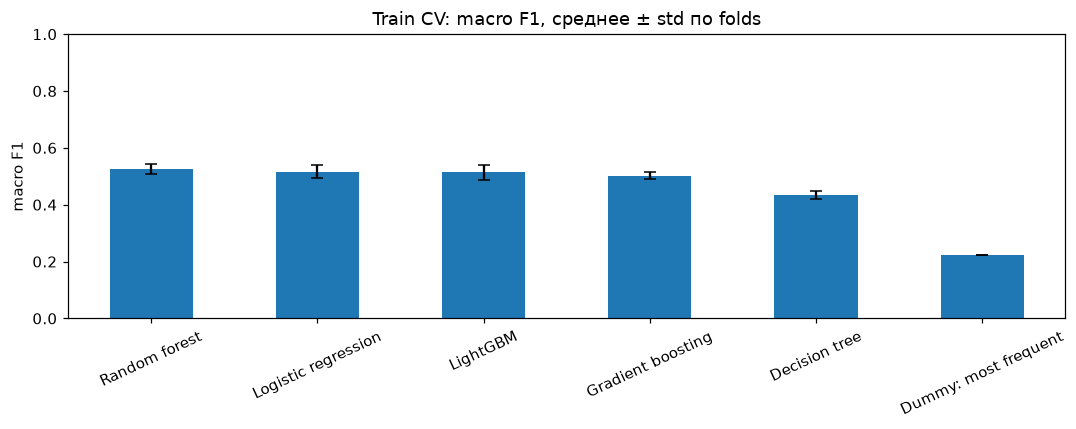

In [12]:
def selected_search_row(name, search):
    i = search.best_index_
    results = search.cv_results_
    split_macro = np.array([
        results[f"split{k}_test_macro_f1"][i] for k in range(N_SPLITS)
    ])
    return {
        "Model": name,
        "CV macro F1 mean": split_macro.mean(),
        "CV macro F1 std": split_macro.std(ddof=1),
        "CV balanced accuracy": results["mean_test_balanced_accuracy"][i],
        "CV Dropout precision": results["mean_test_dropout_precision"][i],
        "CV Dropout recall": results["mean_test_dropout_recall"][i],
        "Train macro F1": results["mean_train_macro_f1"][i],
    }

ensemble_rows = [selected_search_row(name, search) for name, search in searches.items()]
ensemble_cv_table = pd.DataFrame(ensemble_rows).set_index("Model")

cv_comparison = pd.concat([baseline_cv_table, ensemble_cv_table], axis=0)
cv_comparison = cv_comparison.sort_values("CV macro F1 mean", ascending=False)

display(cv_comparison.round(4))

ax = cv_comparison["CV macro F1 mean"].plot.bar(
    yerr=cv_comparison["CV macro F1 std"],
    capsize=4,
    figsize=(10, 4),
    rot=25,
)
ax.set(
    ylim=(0, 1),
    ylabel="macro F1",
    xlabel="",
    title="Train CV: macro F1, среднее ± std по folds",
)
plt.tight_layout()
plt.show()

#### 12. Фиксируем победителя до test¶
Dummy - только нижняя точка отсчёта. Среди реальных моделей выбираем максимальный CV macro F1 mean. Никакие test-метрики в выборе не участвуют.

In [13]:
real_models = cv_comparison.drop(index="Dummy: most frequent")
best_name = real_models["CV macro F1 mean"].idxmax()

if best_name in searches:
    best_model = searches[best_name].best_estimator_
else:
    best_model = clone(baseline_models[best_name]).fit(X_train, y_train)

best_cv = cv_comparison.loc[best_name]

display(Markdown(
    f"**Победитель по train CV: {best_name}.** "
    f"Macro F1 = {best_cv['CV macro F1 mean']:.3f} ± {best_cv['CV macro F1 std']:.3f}; "
    f"CV Dropout precision = {best_cv['CV Dropout precision']:.3f}; "
    f"CV Dropout recall = {best_cv['CV Dropout recall']:.3f}."
))

**Победитель по train CV: Random forest.** Macro F1 = 0.527 ± 0.017; CV Dropout precision = 0.560; CV Dropout recall = 0.551.

#### 13. Финальная test-оценка
Только теперь используем X_test, y_test. Параметры и победителя после этого не меняем.

In [14]:
y_pred = best_model.predict(X_test)

report = classification_report(
    y_test,
    y_pred,
    labels=CLASS_ORDER,
    output_dict=True,
    zero_division=0,
)
cm = confusion_matrix(y_test, y_pred, labels=CLASS_ORDER)

test_metrics = pd.Series({
    "Test macro F1": f1_score(y_test, y_pred, average="macro"),
    "Test weighted F1": f1_score(y_test, y_pred, average="weighted"),
    "Test balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Test accuracy": accuracy_score(y_test, y_pred),
    "Test Dropout precision": report["Dropout"]["precision"],
    "Test Dropout recall": report["Dropout"]["recall"],
    "Test Dropout F1": report["Dropout"]["f1-score"],
}, name=best_name)

display(test_metrics.to_frame().round(4))
print(classification_report(
    y_test,
    y_pred,
    labels=CLASS_ORDER,
    digits=3,
    zero_division=0,
))

,Random forest
Test macro F1,0.4938
Test weighted F1,0.5453
Test balanced accuracy,0.4975
Test accuracy,0.5379
Test Dropout precision,0.5243
Test Dropout recall,0.5317
Test Dropout F1,0.5280


              precision    recall  f1-score   support

     Dropout      0.524     0.532     0.528       284
    Enrolled      0.283     0.352     0.314       159
    Graduate      0.674     0.609     0.640       442

    accuracy                          0.538       885
   macro avg      0.494     0.497     0.494       885
weighted avg      0.556     0.538     0.545       885



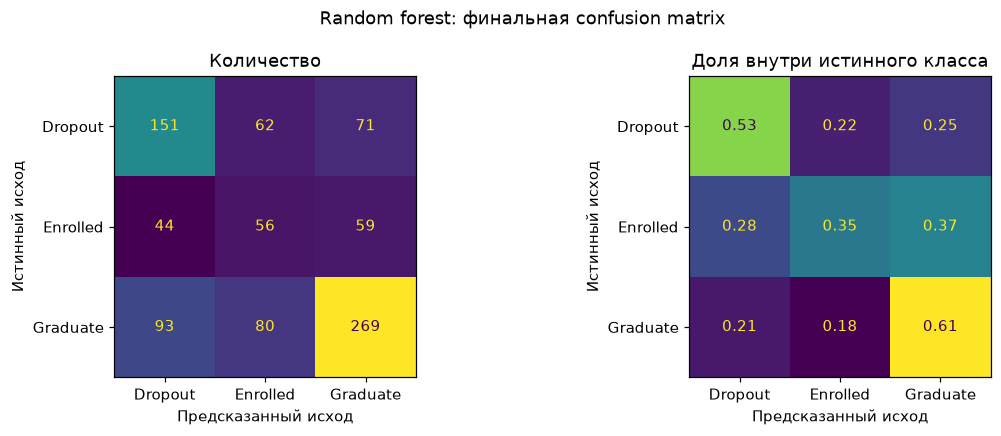

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=CLASS_ORDER,
    normalize=None,
    colorbar=False,
    ax=axes[0],
    values_format="d",
)
axes[0].set_title("Количество")
axes[0].set_xlabel("Предсказанный исход")
axes[0].set_ylabel("Истинный исход")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=CLASS_ORDER,
    normalize="true",
    colorbar=False,
    ax=axes[1],
    values_format=".2f",
)
axes[1].set_title("Доля внутри истинного класса")
axes[1].set_xlabel("Предсказанный исход")
axes[1].set_ylabel("Истинный исход")

fig.suptitle(f"{best_name}: финальная confusion matrix")
plt.tight_layout()
plt.show()

#### 14. Анализ ошибок - какие классы путаются
В многоклассовой задаче ошибка Dropout - это не только Dropout → Graduate: прогноз Dropout → Enrolled тоже означает пропущенный риск, если приглашение на поддержку получают только предсказанные Dropout.  Но Graduate/Enrolled → Dropout создают ложные тревоги.

In [16]:
error_rows = []
for true_i, true_label in enumerate(CLASS_ORDER):
    row_total = cm[true_i].sum()
    for pred_i, pred_label in enumerate(CLASS_ORDER):
        if true_label == pred_label:
            continue
        error_rows.append({
            "Истинный класс": true_label,
            "Предсказанный класс": pred_label,
            "Количество": int(cm[true_i, pred_i]),
            "Доля истинного класса": cm[true_i, pred_i] / row_total,
        })

error_table = (
    pd.DataFrame(error_rows)
    .sort_values(["Количество", "Доля истинного класса"], ascending=False)
    .reset_index(drop=True)
)
display(error_table.round(3))

idx_d = CLASS_ORDER.index("Dropout")
false_negative_dropout = int(cm[idx_d].sum() - cm[idx_d, idx_d])
false_positive_dropout = int(cm[:, idx_d].sum() - cm[idx_d, idx_d])

support_error_summary = pd.Series({
    "Реальных Dropout": int(cm[idx_d].sum()),
    "Найдено Dropout": int(cm[idx_d, idx_d]),
    "Пропущено Dropout (FN)": false_negative_dropout,
    "Ложных сигналов Dropout (FP)": false_positive_dropout,
    "Recall Dropout": report["Dropout"]["recall"],
    "Precision Dropout": report["Dropout"]["precision"],
})
display(support_error_summary.to_frame(name="Значение").round(4))

,Истинный класс,Предсказанный класс,Количество,Доля истинного класса
0,Graduate,Dropout,93,0.210
1,Graduate,Enrolled,80,0.181
2,Dropout,Graduate,71,0.250
3,Dropout,Enrolled,62,0.218
4,Enrolled,Graduate,59,0.371
5,Enrolled,Dropout,44,0.277


,Значение
Реальных Dropout,284.0000
Найдено Dropout,151.0000
Пропущено Dropout (FN),133.0000
Ложных сигналов Dropout (FP),137.0000
Recall Dropout,0.5317
Precision Dropout,0.5243


#### 15. Для ранней поддержки важны и Recall, и Precision класса Dropout
Нельзя смотреть только на общий macro F1. Он нужен как единая метрика выбора модели в этом задании, но перед практическим использованием отдельно проверяем precision/recall Dropout. Если бизнес-цель позже потребует повысить recall, порог по P(Dropout) следует настраивать по OOF/validation-прогнозам train, а не по test.

#### 16. Важность признаков у ансамблей
Random Forest, Gradient Boosting и LightGBM после one-hot работают с большим числом dummy-столбцов. Чтобы результат был читаемым, суммируем feature_importances_ dummy-столбцов обратно до исходных 18 признаков.


Random forest


,Feature,Importance
0,Course,0.1617
1,Application mode,0.1308
2,Age at enrollment,0.1087
3,Gender,0.0741
4,Mother's occupation,0.0704
5,Admission grade,0.0694
6,Father's occupation,0.0669
7,Previous qualification (grade),0.0655
8,Mother's qualification,0.0594
9,Father's qualification,0.0546


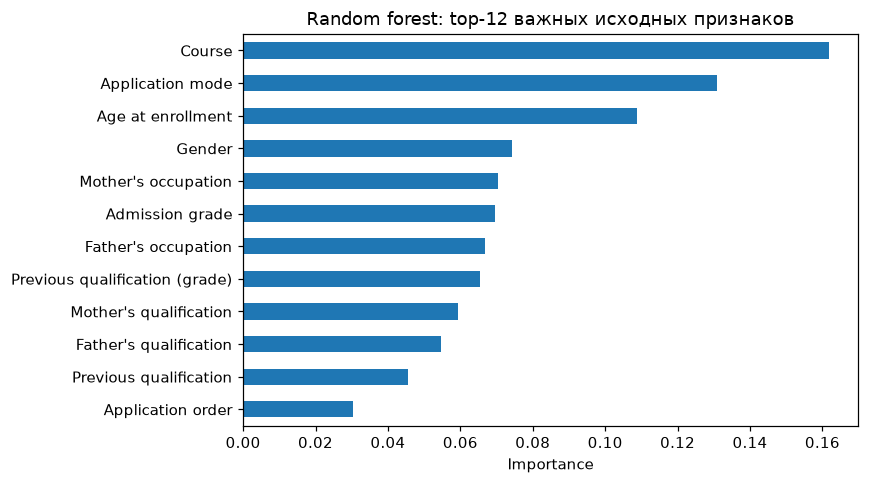


Gradient boosting


,Feature,Importance
0,Course,0.1792
1,Application mode,0.1121
2,Age at enrollment,0.0961
3,Admission grade,0.0867
4,Previous qualification (grade),0.0753
5,Mother's occupation,0.0731
6,Father's occupation,0.0719
7,Father's qualification,0.0653
8,Gender,0.0556
9,Mother's qualification,0.0541


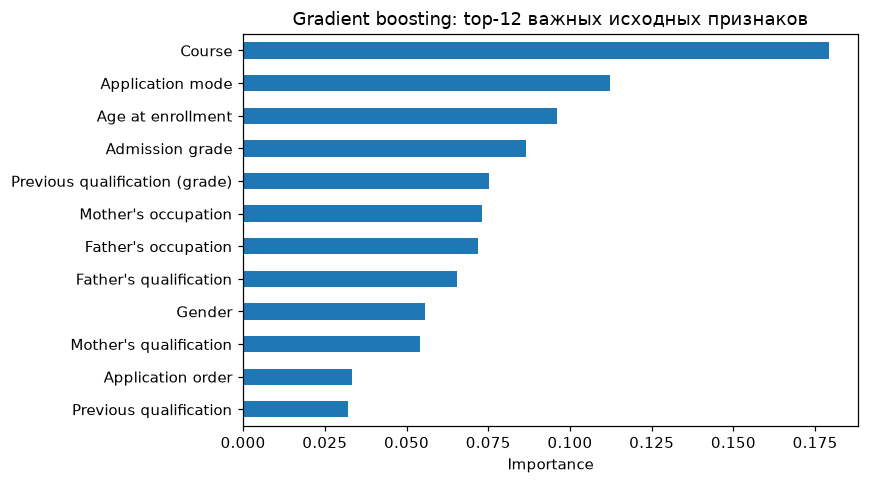


LightGBM


,Feature,Importance
0,Admission grade,2835.0
1,Previous qualification (grade),2234.0
2,Course,1980.0
3,Age at enrollment,1638.0
4,Mother's occupation,1258.0
5,Application mode,1236.0
6,Father's occupation,1161.0
7,Mother's qualification,1123.0
8,Father's qualification,928.0
9,Application order,563.0


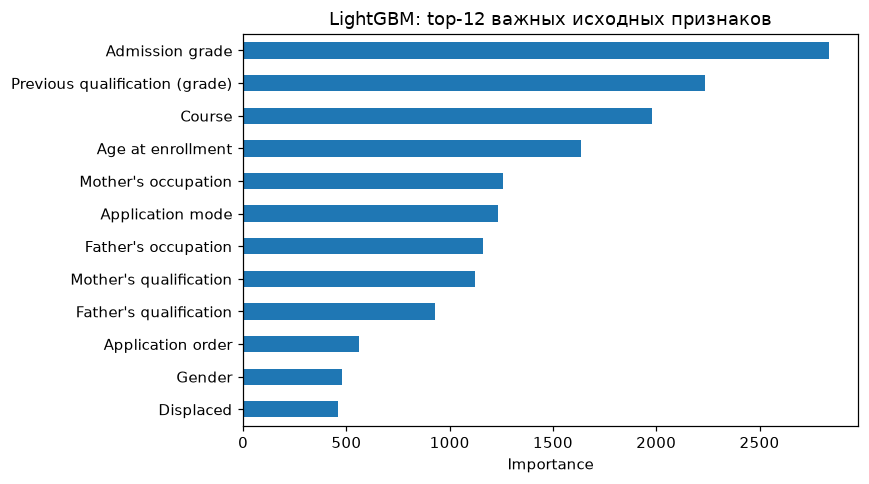

In [17]:
def aggregated_ohe_importance(fitted_pipeline):
    """Суммировать feature_importances_ one-hot модели до исходных признаков."""
    preprocessor = fitted_pipeline.named_steps["preprocessor"]
    model = fitted_pipeline.named_steps["model"]
    importance = np.asarray(model.feature_importances_, dtype=float)

    onehot = preprocessor.named_transformers_["cat"].named_steps["onehot"]
    source_features = []
    for feature, categories in zip(CAT_FEATURES, onehot.categories_):
        source_features.extend([feature] * len(categories))
    source_features.extend(NUM_FEATURES)

    assert len(source_features) == len(importance)

    return (
        pd.DataFrame({"Feature": source_features, "Importance": importance})
        .groupby("Feature", as_index=False)["Importance"]
        .sum()
        .sort_values("Importance", ascending=False)
        .reset_index(drop=True)
    )


importance_tables = {}
for name in ["Random forest", "Gradient boosting", "LightGBM"]:
    importance_tables[name] = aggregated_ohe_importance(searches[name].best_estimator_)

for name, table in importance_tables.items():
    print(f"\n{name}")
    display(table.head(12).round(4))
    ax = table.head(12).sort_values("Importance").plot.barh(
        x="Feature", y="Importance", legend=False, figsize=(8, 4.5)
    )
    ax.set(title=f"{name}: top-12 важных исходных признаков", xlabel="Importance", ylabel="")
    plt.tight_layout()
    plt.show()

#### 17. Решение для ранней поддержки
Модель выбирается до test по максимальному среднему CV macro F1 (best_name). Это соблюдает единый критерий сравнения трёхклассовой классификации и не позволяет многочисленному классу Graduate полностью доминировать над выбором.  
После выбора смотрим test Dropout precision и Dropout recall как operational check:
* если recall слишком низок, система пропускает слишком много будущих Dropout;
* если precision слишком низок, слишком большая часть ресурсов поддержки расходуется на ложные тревоги;
* приемлемый баланс зависит от стоимости контакта, пропускной способности команды поддержки и формы коммуникации.  

In [18]:
decision_summary = pd.Series({
    "Выбранная модель": best_name,
    "CV macro F1 mean": cv_comparison.loc[best_name, "CV macro F1 mean"],
    "CV macro F1 std": cv_comparison.loc[best_name, "CV macro F1 std"],
    "CV Dropout precision": cv_comparison.loc[best_name, "CV Dropout precision"],
    "CV Dropout recall": cv_comparison.loc[best_name, "CV Dropout recall"],
    "Test macro F1": test_metrics["Test macro F1"],
    "Test weighted F1": test_metrics["Test weighted F1"],
    "Test balanced accuracy": test_metrics["Test balanced accuracy"],
    "Test Dropout precision": test_metrics["Test Dropout precision"],
    "Test Dropout recall": test_metrics["Test Dropout recall"],
})
display(decision_summary.to_frame(name="Значение").round(4))

,Значение
Выбранная модель,Random forest
CV macro F1 mean,0.526622
CV macro F1 std,0.017358
CV Dropout precision,0.559729
CV Dropout recall,0.550502
Test macro F1,0.493804
Test weighted F1,0.545288
Test balanced accuracy,0.497496
Test Dropout precision,0.524306
Test Dropout recall,0.53169


#### 18. Проверки отсутствия утечки

In [19]:
assert set(X_train.columns) == set(ALLOWLIST)
assert set(X_test.columns) == set(ALLOWLIST)
assert set(ALLOWLIST).isdisjoint(SEMESTER_FEATURES)

for name in ["Random forest", "Gradient boosting", "LightGBM"]:
    fitted = searches[name].best_estimator_
    prep = fitted.named_steps["preprocessor"]
    assert list(prep.feature_names_in_) == ALLOWLIST
    encoder = prep.named_transformers_["cat"].named_steps["onehot"]
    for feature, categories in zip(CAT_FEATURES, encoder.categories_):
        assert set(categories) == set(X_train[feature].dropna().unique())
    print(f"{name}: проверки pipeline пройдены")

assert cm.sum() == len(y_test)
print("Финальная confusion matrix содержит весь test:", cm.sum())

Random forest: проверки pipeline пройдены
Gradient boosting: проверки pipeline пройдены
LightGBM: проверки pipeline пройдены
Финальная confusion matrix содержит весь test: 885
